# Un LSTM prédit-il la Bourse mieux qu'une baseline naïve ?

Ce notebook part d'un tutoriel YouTube et le corrige étape par étape.

## 1. Imports et paramètres

Le ticker, les dates et la graine aléatoire sont fixés pour que chaque exécution donne exactement les mêmes résultats.

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

import warnings
warnings.filterwarnings("ignore", module="yfinance")   # avertissements internes à yfinance, hors de notre contrôle

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [3]:
ticker = "AMZN"
date = "2020-01-01"
end_date = "2026-11-01"       # date de fin fixe : les données ne bougeront plus
torch.manual_seed(42)

df = yf.download(ticker, start=date, end=end_date)


[*********************100%***********************]  1 of 1 completed


In [4]:
df.head()

Price,Close,High,Low,Open,Volume
Ticker,AMZN,AMZN,AMZN,AMZN,AMZN
Date,,,,,
2020-01-02,94.900497,94.900497,93.207497,93.750000,80580000
2020-01-03,93.748497,94.309998,93.224998,93.224998,75288000
2020-01-06,95.143997,95.184502,93.000000,93.000000,81236000
2020-01-07,95.343002,95.694504,94.601997,95.224998,80898000
2020-01-08,94.598503,95.550003,94.321999,94.902000,70160000


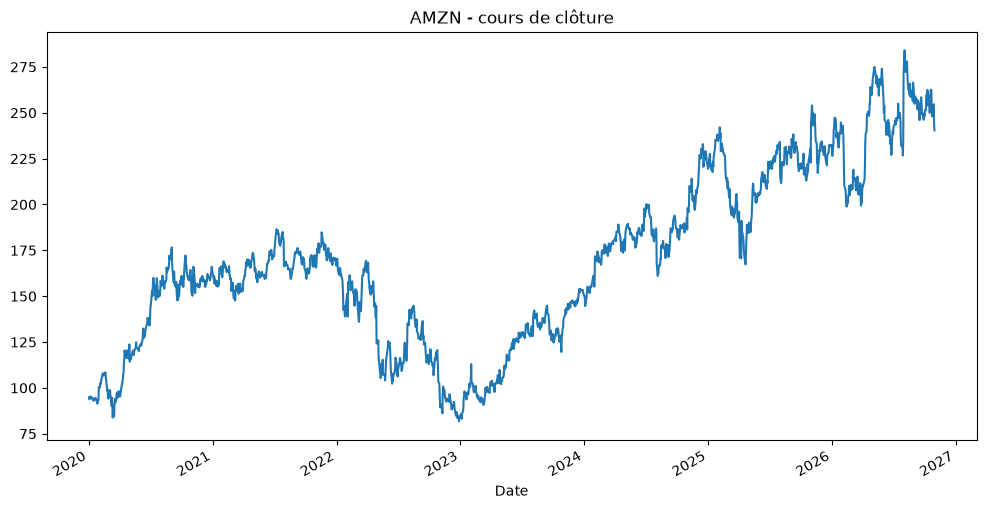

In [5]:
df.Close.plot(figsize=(12, 6), title=f"{ticker} - cours de clôture", legend=False);

## 2. Des prix aux log-rendements

Le tuto prédit le prix brut, qui dérive dans le temps : le modèle apprend sur une plage de valeurs et doit prédire sur une autre. On prédit plutôt le log-rendement journalier, qui oscille autour de zéro quelle que soit la période.

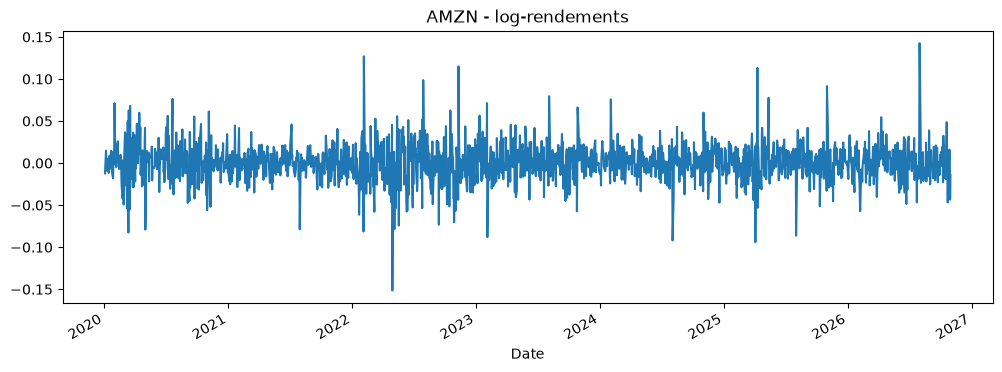

In [6]:
df['Close'] = np.log(df['Close']).diff()   # remplace le prix par le log-rendement
df = df.dropna()                            # le 1er jour n'a pas de veille -> NaN
df.Close.plot(figsize=(12, 4), title=f"{ticker} - log-rendements", legend=False);

## 3. Normalisation sans fuite de données

Le tuto ajuste le scaler sur toute la série, ce qui donne au modèle des informations sur la période de test. Ici, il est ajusté sur le train seulement, puis appliqué à toute la série.

In [7]:
seq_length = 30
train_size = int(0.8 * (len(df) - seq_length))   # nombre de fenêtres d'entraînement (80 %)
n_train_rows = train_size + seq_length - 1       # lignes couvertes par les fenêtres de train

scaler = StandardScaler()
scaler.fit(df['Close'].iloc[:n_train_rows])      # moyenne et écart-type du train SEUL
df['Close'] = scaler.transform(df['Close'])      # appliqués ensuite à toute la série

## 4. Fenêtres glissantes et découpage chronologique

Chaque exemple contient 29 jours de rendements en entrée, et le 30e en cible. Le découpage train / test est chronologique (80 % / 20 %), sans mélange : on ne doit jamais entraîner sur le futur pour prédire le passé.

In [8]:
data = []
for i in range(len(df) - seq_length):          # une fenêtre par jour, décalée d'un jour à chaque fois
    data.append(df.Close[i:i+seq_length])
data = np.array(data)                          # forme : (nb_fenêtres, 30 jours, 1 variable)

In [9]:
# :-1 = les 29 premiers jours (entrée) ; -1 = le 30e jour (cible)
x_train = torch.from_numpy(data[:train_size, :-1, :]).type(torch.Tensor).to(device)
y_train = torch.from_numpy(data[:train_size, -1, :]).type(torch.Tensor).to(device)
x_test = torch.from_numpy(data[train_size:, :-1, :]).type(torch.Tensor).to(device)
y_test = torch.from_numpy(data[train_size:, -1, :]).type(torch.Tensor).to(device)

## 5. Le modèle LSTM

Deux couches LSTM de 32 neurones, suivies d'une couche linéaire qui prédit le rendement du lendemain à partir de la sortie du dernier jour de la fenêtre.

In [10]:
class PredictionModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
        super(PredictionModel,self).__init__()
        
        self.num_layers = num_layers
        self.hidden_dim = hidden_dim
        
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)
    
    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device=device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device=device)
        out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
        out=self.fc(out[:,-1,:])
        return out

In [11]:
model = PredictionModel(input_dim=1, hidden_dim=32, num_layers=2, output_dim=1).to(device)

In [12]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(),lr=0.01)

## 6. Entraînement avec early stopping

Le tuto entraîne le modèle 200 époques sans contrôle, ce qui provoque un fort surapprentissage. Les 20 % les plus récents du train servent ici de jeu de validation : on garde la meilleure version et on arrête après 20 époques sans progrès.

In [13]:
val_size = int(0.2 * len(x_train))      # les 20 % les plus récents du train
x_tr, y_tr = x_train[:-val_size], y_train[:-val_size]
x_val, y_val = x_train[-val_size:], y_train[-val_size:]

In [14]:
import copy

num_epochs = 200
best_val, best_state, patience, wait = float('inf'), None, 20, 0

for i in range(num_epochs):
    model.train()
    optimizer.zero_grad()
    loss = criterion(model(x_tr), y_tr)
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        val_loss = criterion(model(x_val), y_val).item()

    if val_loss < best_val:              # nouveau meilleur modèle : on le sauvegarde
        best_val, best_state, wait = val_loss, copy.deepcopy(model.state_dict()), 0
    else:
        wait += 1
        if wait >= patience:             # 20 époques sans progrès : on arrête
            print(f"Arrêt anticipé à l'époque {i}")
            break

    if i % 25 == 0:
        print(f"{i:3d} | train {loss.item():.4f} | val {val_loss:.4f}")

model.load_state_dict(best_state)        # on revient à la meilleure version

  0 | train 1.0444 | val 0.8953
 25 | train 1.0387 | val 0.8816
Arrêt anticipé à l'époque 27


<All keys matched successfully>

## 7. Évaluation face à des baselines simples

Un RMSE seul ne veut rien dire. On compare le LSTM à trois concurrents :
- **zéro** : « demain, le rendement sera nul » ;
- **moyenne** : le rendement moyen du train, répété chaque jour ;
- **régression linéaire** sur les 29 derniers rendements.

On mesure aussi la précision de direction (hausse ou baisse), comparée à la baseline « toujours hausse ».

In [15]:
model.eval()
with torch.no_grad():
    y_train_pred = model(x_train)
    y_test_pred = model(x_test)

# retour à l'échelle des vrais rendements ; nouveaux noms pour ne pas écraser les tenseurs
y_train_pred = scaler.inverse_transform(y_train_pred.cpu().numpy())
y_test_pred = scaler.inverse_transform(y_test_pred.cpu().numpy())
y_train_true = scaler.inverse_transform(y_train.cpu().numpy())
y_test_true = scaler.inverse_transform(y_test.cpu().numpy())

In [16]:
train_rmse = root_mean_squared_error(y_train_true[:, 0], y_train_pred[:, 0])
test_rmse = root_mean_squared_error(y_test_true[:, 0], y_test_pred[:, 0])

In [17]:
zero_pred = np.zeros_like(y_test_true)                  # baseline : rendement nul
zero_rmse = root_mean_squared_error(y_test_true[:, 0], zero_pred[:, 0])

def direction_acc(y_true, y_pred):
    return np.mean((y_true > 0) == (y_pred > 0))   # % de bon sens hausse/baisse

print(f"RMSE LSTM : {test_rmse:.5f}")
print(f"RMSE zéro : {zero_rmse:.5f}")
print(f"Direction LSTM : {direction_acc(y_test_true, y_test_pred):.1%}")
print(f"Direction 'toujours hausse' : {np.mean(y_test_true > 0):.1%}")

RMSE LSTM : 0.02073
RMSE zéro : 0.02073
Direction LSTM : 52.1%
Direction 'toujours hausse' : 51.8%


In [18]:
from sklearn.linear_model import LinearRegression

# sklearn attend des tableaux 2D (n_exemples, n_variables) : on retire la 3e dimension
X_lin_train = x_train.cpu().numpy()[:, :, 0]
X_lin_test = x_test.cpu().numpy()[:, :, 0]

lin = LinearRegression().fit(X_lin_train, y_train.cpu().numpy())
lin_pred = scaler.inverse_transform(lin.predict(X_lin_test))

mean_pred = np.full_like(y_test_true, y_train_true.mean())

def rmse(pred):
    return root_mean_squared_error(y_test_true[:, 0], pred[:, 0])

results = pd.DataFrame({
    "Modèle": ["Zéro", "Moyenne train", "Régression linéaire", "LSTM"],
    "RMSE": [rmse(zero_pred), rmse(mean_pred), rmse(lin_pred), rmse(y_test_pred)],
    "Direction": [np.nan,                       # prédire 0 ne donne aucun sens
                  direction_acc(y_test_true, mean_pred),
                  direction_acc(y_test_true, lin_pred),
                  direction_acc(y_test_true, y_test_pred)],
})
results.round(5)

,Modèle,RMSE,Direction
0,Zéro,0.02073,NaN
1,Moyenne train,0.02072,0.51775
2,Régression linéaire,0.02084,0.50000
3,LSTM,0.02073,0.52071


**Résultat sur Amazon** : le LSTM obtient exactement le même RMSE que la baseline zéro (0,0207). Dans la version du tuto, sans early stopping, il faisait 35 % pire.

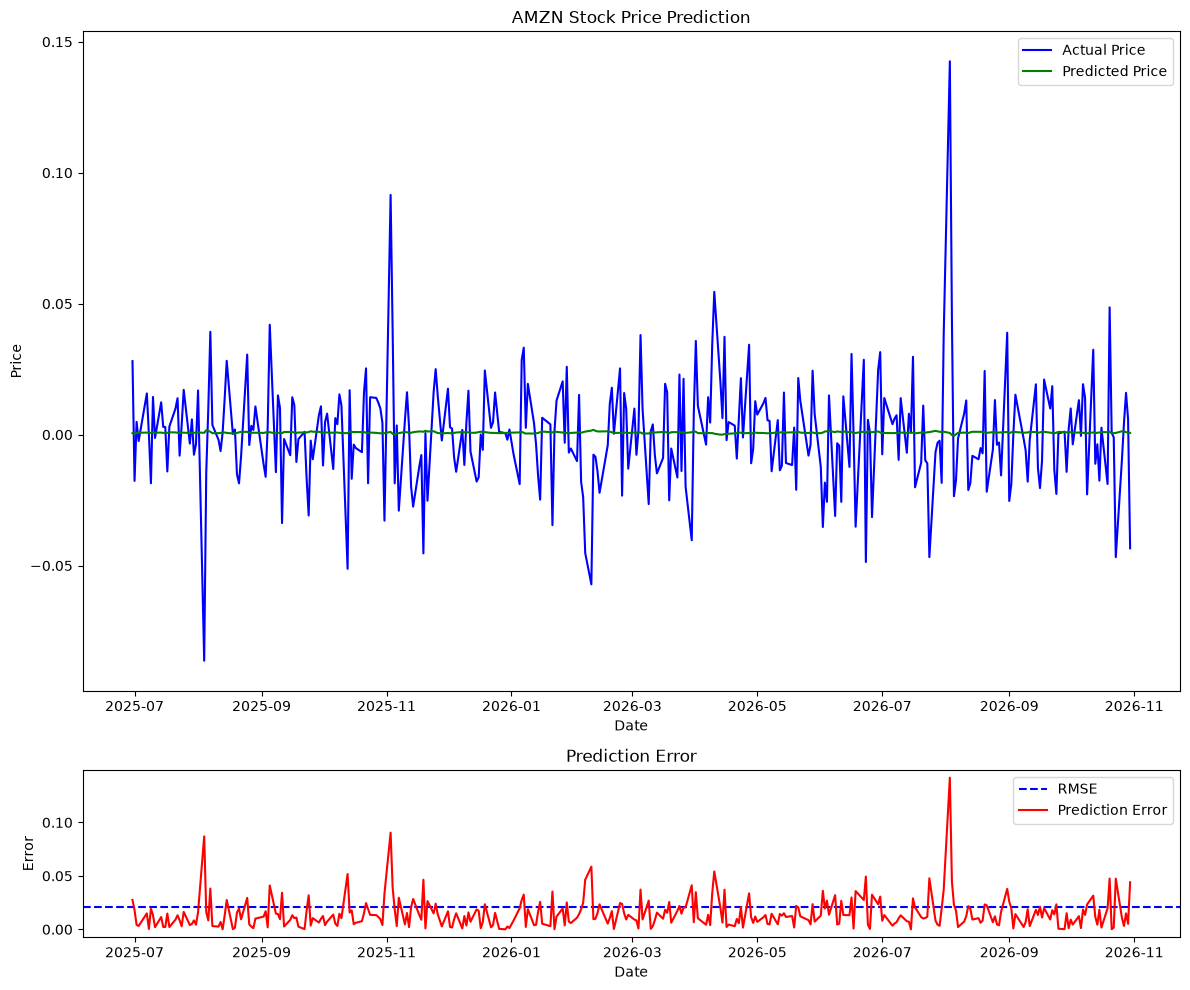

In [19]:
fig = plt.figure(figsize=(12, 10))
gs = fig.add_gridspec(4, 1)
axl = fig.add_subplot(gs[:3, 0])
axl.plot(df.iloc[-len(y_test_true):].index, y_test_true, color = 'blue', label = 'Actual Price')
axl.plot(df.iloc[-len(y_test_true):].index, y_test_pred, color = 'green', label = 'Predicted Price')
axl.legend()
plt.title(f"{ticker} Stock Price Prediction")
plt.xlabel('Date')
plt.ylabel('Price')
ax2 = fig.add_subplot(gs[3, 0])
ax2.axhline(test_rmse, color = 'blue', linestyle = '--', label = 'RMSE')
ax2.plot(df.iloc[-len(y_test_true):].index, np.abs(y_test_true - y_test_pred), 'r', label = 'Prediction Error')
ax2.legend()
plt.title('Prediction Error')
plt.xlabel('Date')
plt.ylabel('Error')
plt.tight_layout()

plt.show()

## 8. Robustesse sur 7 actifs

Pour vérifier que le résultat n'est pas propre à Amazon, tout le pipeline est regroupé dans `benchmark.py` et appliqué à 7 actifs de profils différents : actions technologiques, banque, valeur défensive, action française et indice.

In [20]:
%load_ext autoreload
%autoreload 2
from benchmark import run_benchmark

In [21]:
tickers = ["AMZN", "AAPL", "MSFT", "JPM", "KO", "MC.PA", "^GSPC"]

rows = []
for t in tickers:
    print(f"{t}...")
    try:
        rows.append(run_benchmark(t))
    except Exception as e:
        print(f"  {t} ignoré : {e}")

results_all = pd.DataFrame(rows).set_index("Ticker")
results_all.round(4)

AMZN...
AAPL...
MSFT...
JPM...
KO...
MC.PA...
^GSPC...


,Jours test,RMSE zéro,RMSE moyenne,RMSE linéaire,RMSE LSTM,LSTM vs zéro (%),Dir. toujours hausse,Dir. linéaire,Dir. LSTM,Époque d'arrêt
Ticker,,,,,,,,,,
AMZN,338,0.0207,0.0207,0.0208,0.0207,0.0383,0.5178,0.5000,0.5207,27
AAPL,338,0.0153,0.0152,0.0155,0.0153,-0.0620,0.5414,0.4763,0.5118,42
MSFT,338,0.0183,0.0184,0.0193,0.0184,0.1269,0.5030,0.5148,0.4941,21
JPM,338,0.0133,0.0133,0.0139,0.0134,0.6850,0.5562,0.4852,0.5592,47
KO,338,0.0114,0.0113,0.0116,0.0113,-0.3272,0.5059,0.4911,0.5059,62
MC.PA,344,0.0186,0.0186,0.0189,0.0187,0.4772,0.4651,0.4738,0.5349,20
^GSPC,338,0.0076,0.0076,0.0079,0.0076,0.1491,0.5444,0.5000,0.5207,59


In [22]:
results_all.iloc[:, :6].round(4)   # les RMSE

,Jours test,RMSE zéro,RMSE moyenne,RMSE linéaire,RMSE LSTM,LSTM vs zéro (%)
Ticker,,,,,,
AMZN,338,0.0207,0.0207,0.0208,0.0207,0.0383
AAPL,338,0.0153,0.0152,0.0155,0.0153,-0.0620
MSFT,338,0.0183,0.0184,0.0193,0.0184,0.1269
JPM,338,0.0133,0.0133,0.0139,0.0134,0.6850
KO,338,0.0114,0.0113,0.0116,0.0113,-0.3272
MC.PA,344,0.0186,0.0186,0.0189,0.0187,0.4772
^GSPC,338,0.0076,0.0076,0.0079,0.0076,0.1491


In [23]:
results_all.iloc[:, 6:].round(4)   # l'écart, les directions et l'époque d'arrêt

,Dir. toujours hausse,Dir. linéaire,Dir. LSTM,Époque d'arrêt
Ticker,,,,
AMZN,0.5178,0.5000,0.5207,27
AAPL,0.5414,0.4763,0.5118,42
MSFT,0.5030,0.5148,0.4941,21
JPM,0.5562,0.4852,0.5592,47
KO,0.5059,0.4911,0.5059,62
MC.PA,0.4651,0.4738,0.5349,20
^GSPC,0.5444,0.5000,0.5207,59


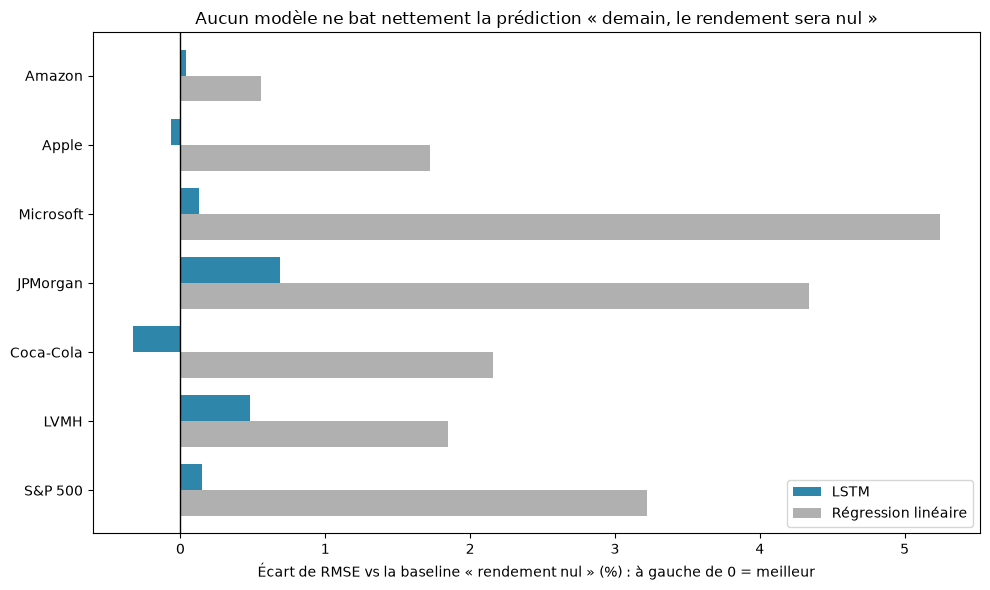

In [24]:
import os

names = {"AMZN": "Amazon", "AAPL": "Apple", "MSFT": "Microsoft", "JPM": "JPMorgan",
         "KO": "Coca-Cola", "MC.PA": "LVMH", "^GSPC": "S&P 500"}

ecarts = pd.DataFrame({
    "LSTM": results_all["LSTM vs zéro (%)"],
    "Régression linéaire": 100 * (results_all["RMSE linéaire"] / results_all["RMSE zéro"] - 1),
}).rename(index=names)

ax = ecarts.plot.barh(figsize=(10, 6), color=["#2E86AB", "#B0B0B0"], width=0.75)
ax.axvline(0, color="black", linewidth=1)
ax.invert_yaxis()
ax.set_xlabel("Écart de RMSE vs la baseline « rendement nul » (%) : à gauche de 0 = meilleur")
ax.set_ylabel("")
ax.set_title("Aucun modèle ne bat nettement la prédiction « demain, le rendement sera nul »")
ax.legend(loc="lower right")
plt.tight_layout()

os.makedirs("reports/figures", exist_ok=True)
plt.savefig("reports/figures/benchmark_ecarts.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Conclusion

Sur les 7 actifs, aucun modèle ne bat nettement la baseline zéro : le LSTM reste à moins de 0,7 % de son RMSE. Les rendements passés ne contiennent pas d'information exploitable pour prédire le lendemain, ce qui est cohérent avec l'hypothèse d'efficience des marchés. Les limites de l'étude sont détaillées dans le README.